# CDS 4003: Mobile Game In-App Purchases

## Stage 5: Model Selection and Development

**Models Implemented:** Random Forest and NLP (Tabular-to-Text TF-IDF + Logistic Regression)

## Model 1: Random Forest Classifier

In this section, we train a Random Forest classifier to predict `SpendingSegment` (`Minnow`, `Dolphin`, `Whale`) on the dataset (`mobile_game_players_eda_features.csv`) with 247,500 rows split 80/20 (`198,000` training and `49,500` test rows).

- **Preprocessing & Leakage Prevention:** Excluded identifier, direct spending, date, and derived summary leakage columns, used a manual 20-feature subset, and enclosed `ColumnTransformer` (`passthrough` on numeric features and `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` on categorical features) inside scikit-learn `Pipeline` objects so preprocessing is fit strictly within each fold during cross-validation and hyperparameter tuning.
- **Handling Class Imbalance:** Applied `class_weight="balanced"` to account for the skewed `SpendingSegment` distribution (~84.17% `Minnow`, ~13.60% `Dolphin`, ~2.22% `Whale`) so minority segments (`Dolphin` and `Whale`) receive stronger weight during training.
- **Cross-Validation & Hyperparameter Tuning:** Evaluated a baseline pipeline (`n_estimators=80`, `max_depth=15`, `min_samples_leaf=5`, `class_weight="balanced"`) using 3-fold `StratifiedKFold` cross-validation (`f1_macro`, mean `0.6359`), then tuned hyperparameters inside a `Pipeline` with `RandomizedSearchCV` (`n_iter=6`, `scoring="f1_macro"`), selecting `{'model__n_estimators': 120, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 15, 'model__criterion': 'entropy'}` with a best CV Macro-F1 of `0.6457`.
- **Evaluation & Feature Importance:** Evaluated baseline vs. tuned performance on the held-out test set (`Accuracy`, `Balanced Accuracy`, `Macro-F1`, `classification_report`, and `confusion_matrix`), achieving a tuned test `Accuracy` of `0.7837`, `Balanced Accuracy` of `0.7672`, `Macro-F1` of `0.6440`, and `Whale` recall of `0.8491` (`934` out of `1,100`), while extracting feature importances directly from the fitted pipeline steps (`AdsPerActiveDay`, `AdsWatched30d`, `EngagementActionsPerActiveDay`, `EngagementActions30d`, `SocialActions30d`).

In [30]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

In [31]:
# 1. Load Data, Prevent Leakage & Select Manual Features
df = pd.read_csv("mobile_game_players_eda_features.csv", low_memory=False)

target_col = "SpendingSegment"

# Columns excluded to prevent target leakage, purchase-derived leakage, IDs/dates, or simulated features tied to SpendingSegment
leaky_or_excluded_cols = {
    target_col,
    "UserID",
    "InAppPurchaseAmount",
    "IAPForSummary",
    "AmountKnown",
    "InAppPurchaseAmountWasMissing",
    "FirstPurchaseDaysAfterInstall",
    "FirstPurchaseDaysAfterInstallWasMissing",
    "LastPurchaseDate",
    "InstallDate",
    "PaymentMethod",
    "PurchaseCount30d",
    "PurchasesPerActiveDay",
    "HasPurchase30d",
    "AdViewBand",
}

# Manually selected non-leaky behavioral, engagement, gameplay, and profile features
manual_numeric_cols = [
    "Age",
    "SessionCount",
    "AverageSessionLength",
    "ActiveDays30d",
    "PlayerLevel30d",
    "AdsWatched30d",
    "SocialActions30d",
    "WinRate",
    "EngagementActions30d",
    "AdsPerActiveDay",
    "SocialActionsPerActiveDay",
    "SessionsPerActiveDay",
    "EngagementActionsPerActiveDay",
]

manual_categorical_cols = [
    "Gender",
    "Country",
    "Device",
    "GameGenre",
    "AcquisitionChannel",
    "GuildMember",
    "PushNotificationsOptIn",
]

# Ensure no excluded or missing columns slip through
numeric_cols = [c for c in manual_numeric_cols if c not in leaky_or_excluded_cols and c in df.columns]
categorical_cols = [c for c in manual_categorical_cols if c not in leaky_or_excluded_cols and c in df.columns]
selected_features = numeric_cols + categorical_cols

df_model = df[selected_features + [target_col]].dropna().copy()

X = df_model[selected_features].copy()
y = df_model[target_col].copy()

print("Selected Numeric:", numeric_cols)
print("Selected Categorical:", categorical_cols)
print("Shape of X:", X.shape)

Selected Numeric: ['Age', 'SessionCount', 'AverageSessionLength', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'WinRate', 'EngagementActions30d', 'AdsPerActiveDay', 'SocialActionsPerActiveDay', 'SessionsPerActiveDay', 'EngagementActionsPerActiveDay']
Selected Categorical: ['Gender', 'Country', 'Device', 'GameGenre', 'AcquisitionChannel', 'GuildMember', 'PushNotificationsOptIn']
Shape of X: (247500, 20)


In [33]:
# 2. Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [34]:
# Define preprocessor to be fitted inside Pipeline per fold during CV/search
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ]
)

In [35]:
#3. Ensure preprocessor uses the updated numeric_cols and categorical_cols
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ]
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf_baseline_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=80, max_depth=15, min_samples_leaf=5,
        class_weight="balanced", random_state=42, n_jobs=-1
    )),
])

cv_scores = cross_val_score(rf_baseline_pipe, X_train, y_train, cv=cv, scoring="f1_macro", error_score="raise")
print(f"3-Fold CV Macro-F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

rf_baseline_pipe.fit(X_train, y_train)
y_pred_base = rf_baseline_pipe.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_base):.4f} | Balanced Acc: {balanced_accuracy_score(y_test, y_pred_base):.4f} | Macro-F1: {f1_score(y_test, y_pred_base, average='macro', zero_division=0):.4f}")
print(classification_report(y_test, y_pred_base, zero_division=0))

3-Fold CV Macro-F1: 0.6359 (+/- 0.0029)
Accuracy: 0.7700 | Balanced Acc: 0.7675 | Macro-F1: 0.6358
              precision    recall  f1-score   support

     Dolphin       0.34      0.66      0.45      6734
      Minnow       0.95      0.79      0.86     41666
       Whale       0.46      0.85      0.60      1100

    accuracy                           0.77     49500
   macro avg       0.58      0.77      0.64     49500
weighted avg       0.86      0.77      0.80     49500



In [36]:
# 4. Fast Hyperparameter Tuning (RandomizedSearchCV)
param_distributions = {
    "model__n_estimators": [80, 120],
    "model__max_depth": [10, 15, 20],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", "log2"],
    "model__criterion": ["gini", "entropy"],
}

rf_pipe = Pipeline([
    ("preprocess", preprocessor),
    (
        "model",
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=1,  # Keep inner jobs=1 while outer search parallelizes across candidates/folds
        ),
    ),
])

rf_search = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=param_distributions,
    n_iter=6,  # Kept small for fast runtime on ~247.5k rows
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

print(f"Best CV Macro-F1: {rf_search.best_score_:.4f}")
print("Best Hyperparameters:", rf_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best CV Macro-F1: 0.6457
Best Hyperparameters: {'model__n_estimators': 120, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 15, 'model__criterion': 'entropy'}


In [37]:
# 5. Model Evaluation (Tuned Model on Test Set)
y_pred_tuned = best_rf.predict(X_test)
labels_order = ["Minnow", "Dolphin", "Whale"]

print("Tuned Random Forest (Test Set)")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Macro-F1          : {f1_score(y_test, y_pred_tuned, average='macro', zero_division=0):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred_tuned, labels=labels_order, digits=4, zero_division=0))

Tuned Random Forest (Test Set)
Accuracy          : 0.7837
Balanced Accuracy : 0.7672
Macro-F1          : 0.6440
Classification Report:
               precision    recall  f1-score   support

      Minnow     0.9512    0.8037    0.8713     41666
     Dolphin     0.3555    0.6486    0.4593      6734
       Whale     0.4656    0.8491    0.6014      1100

    accuracy                         0.7837     49500
   macro avg     0.5908    0.7672    0.6440     49500
weighted avg     0.8594    0.7837    0.8092     49500



In [38]:
# Side-by-side summary table
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy", "Macro-F1"],
    "Baseline (Before Tuning)": [
        round(accuracy_score(y_test, y_pred_base), 4),
        round(balanced_accuracy_score(y_test, y_pred_base), 4),
        round(f1_score(y_test, y_pred_base, average="macro"), 4),
    ],
    "Tuned (After Tuning)": [
        round(accuracy_score(y_test, y_pred_tuned), 4),
        round(balanced_accuracy_score(y_test, y_pred_tuned), 4),
        round(f1_score(y_test, y_pred_tuned, average="macro"), 4),
    ],
})
print("Before vs After Tuning Summary")
print(comparison_df.to_string(index=False))

Before vs After Tuning Summary
           Metric  Baseline (Before Tuning)  Tuned (After Tuning)
         Accuracy                    0.7700                0.7837
Balanced Accuracy                    0.7675                0.7672
         Macro-F1                    0.6358                0.6440


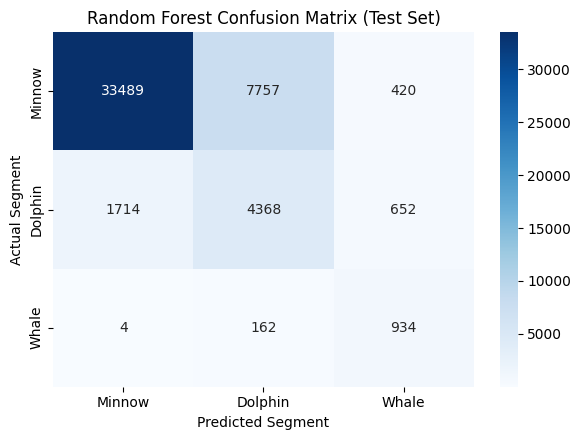

In [39]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned, labels=labels_order)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order)
plt.title("Random Forest Confusion Matrix (Test Set)")
plt.xlabel("Predicted Segment")
plt.ylabel("Actual Segment")
plt.tight_layout()
plt.show()

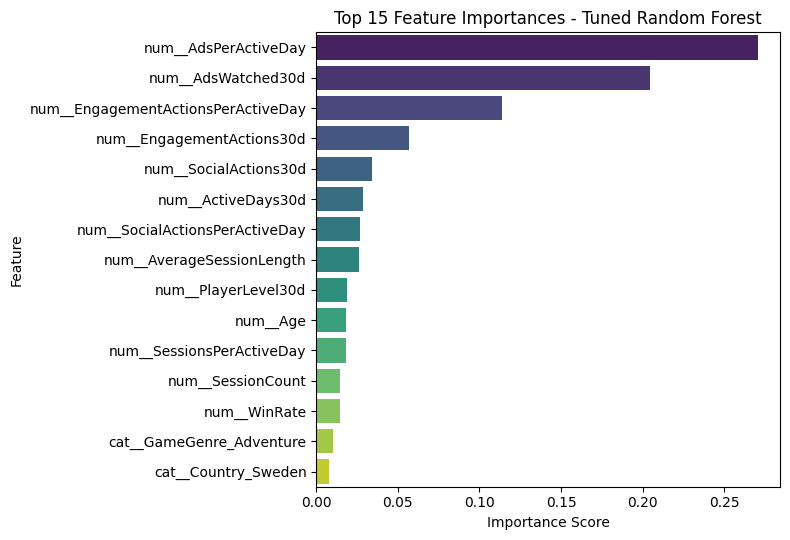

In [41]:
# 6. Visualize Feature Importance
rf_model = best_rf.named_steps["model"]
feature_names = best_rf.named_steps["preprocess"].get_feature_names_out()
importances = rf_model.feature_importances_

fi_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 5.5))
sns.barplot(data=fi_df, x="Importance", y="Feature", hue="Feature", palette="viridis", legend=False)
plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Model 2: NLP Classifier (Tabular-to-Text TF-IDF + Logistic Regression)

**Short Description:** This section demonstrates a tabular-to-text Natural Language Processing (NLP) approach to predict `SpendingSegment` (`Minnow`, `Dolphin`, `Whale`) using generated player profile narratives (`player_profile_text`) built from non-leakage player attributes after dropping missing rows across selected columns[cite: 6, 9, 16].

- **Tabular-to-Text Feature Construction:** Normalized boolean/yes-no attributes (`GuildMember` and `PushNotificationsOptIn`) using `.isin(["yes", "true", "1"])` mapped to readable text phrases and constructed a vectorized `player_profile_text` column from non-leakage profile and 30-day engagement columns (`Age`, `Gender`, `Country`, `GameGenre`, `Device`, `ActiveDays30d`, `SessionCount`, `AverageSessionLength`, `PlayerLevel30d`, `SocialActions30d`, `GuildMember`, `PushNotificationsOptIn`), excluding direct spending and leakage columns[cite: 6, 8, 9].
- **Train-Test Split & Text Vectorization:** Split `player_profile_text` and `SpendingSegment` `80/20` with `stratify=y` and `random_state=42`, then enclosed `TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000, min_df=5)` inside a scikit-learn `Pipeline` with `LogisticRegression` so text feature extraction fits strictly within each training fold[cite: 10, 11].
- **Cross-Validation & Class Balancing:** Evaluated the `Pipeline` (`TfidfVectorizer` + `LogisticRegression(max_iter=500, class_weight="balanced", random_state=42)`) using 3-fold `StratifiedKFold` cross-validation (`scoring="f1_macro"`, `shuffle=True`, `random_state=42`) on the training set, achieving a mean CV Macro-F1 of `0.3318 (+/- 0.0018)` while accounting for class imbalance across `Minnow`, `Dolphin`, and `Whale`[cite: 10, 11].
- **Model Evaluation:** Trained the pipeline on the full training split and evaluated on the held-out test set (`49,500` rows), achieving `Accuracy` of `0.4850`, `Balanced Accuracy` of `0.5241`, and `Macro-F1` of `0.3344`, with `Whale` recall of `0.6991` (`769` out of `1,100`), highlighting the trade-off between narrative text representations and full tabular features[cite: 11, 12].
- **Per-Segment Term Importance:** Extracted the fitted `TfidfVectorizer` vocabulary and `LogisticRegression` coefficients (`classifier.coef_`) from `nlp_pipeline.named_steps` and plotted horizontal bar charts of the top 10 terms/n-grams by coefficient magnitude for `Dolphin`, `Minnow`, and `Whale` (highlighting positive and negative weights) saved to `nlp_feature_importance_per_group.png`[cite: 14, 15].

In [42]:
#1- Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

In [43]:
#2-  Load cleaned dataset
df = pd.read_csv("mobile_game_players_eda_features.csv")

In [44]:
#3-  Select non-leakage profile and engagement columns plus target
required_cols = [
    "Age",
    "Gender",
    "Country",
    "GameGenre",
    "Device",
    "ActiveDays30d",
    "SessionCount",
    "AverageSessionLength",
    "PlayerLevel30d",
    "SocialActions30d",
    "GuildMember",
    "PushNotificationsOptIn",
    "SpendingSegment",
]
df_nlp = df[required_cols].dropna().copy()

In [46]:
#4- Map boolean/yes-no fields into readable text phrases
guild_norm = df_nlp["GuildMember"].astype(str).str.strip().str.lower()
guild_text = (
    guild_norm.isin(["yes", "true", "1"])
    .map({True: "is a guild member", False: "is not a guild member"})
)

notif_norm = df_nlp["PushNotificationsOptIn"].astype(str).str.strip().str.lower()
notif_text = (
    notif_norm.isin(["yes", "true", "1"])
    .map({True: "opts in to push notifications", False: "does not opt in to push notifications"})
)

In [47]:
#5-  Create vectorized player profile text column (avoids row-wise apply overhead)
df_nlp["player_profile_text"] = (
    "This player is a "
    + df_nlp["Age"].astype(str)
    + "-year-old "
    + df_nlp["Gender"].astype(str).str.strip().str.lower()
    + " from "
    + df_nlp["Country"].astype(str).str.strip()
    + " playing "
    + df_nlp["GameGenre"].astype(str).str.strip()
    + " on "
    + df_nlp["Device"].astype(str).str.strip()
    + ". Over 30 days, the player recorded "
    + df_nlp["ActiveDays30d"].astype(str)
    + " active days, "
    + df_nlp["SessionCount"].astype(str)
    + " sessions with an average length of "
    + df_nlp["AverageSessionLength"].round(1).astype(str)
    + " minutes, reached level "
    + df_nlp["PlayerLevel30d"].astype(str)
    + ", and completed "
    + df_nlp["SocialActions30d"].astype(str)
    + " social actions. The player "
    + guild_text
    + " and "
    + notif_text
    + "."
)

print("Sample generated text:\n", df_nlp["player_profile_text"].iloc[0])

Sample generated text:
 This player is a 49.0-year-old male from Norway playing Battle Royale on Android. Over 30 days, the player recorded 5.0 active days, 9.0 sessions with an average length of 12.8 minutes, reached level 4.0, and completed 1.0 social actions. The player is not a guild member and does not opt in to push notifications.


In [48]:
#6-  Split text features and target (80/20 stratified)
X_text = df_nlp["player_profile_text"]
y = df_nlp["SpendingSegment"]

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [49]:
#7- Build TF-IDF + Logistic Regression pipeline with balanced class weights
nlp_pipeline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                max_features=5000,
                min_df=5,
            ),
        ),
        (
            "clf",
            LogisticRegression(
                max_iter=500,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

In [50]:
#8- Run 3-fold Stratified Cross-Validation on training data only
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    nlp_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

print(f"NLP 3-Fold CV Macro-F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

NLP 3-Fold CV Macro-F1: 0.3318 (+/- 0.0018)


In [51]:
#9- Train and evaluate on test set
nlp_pipeline.fit(X_train, y_train)
y_pred = nlp_pipeline.predict(X_test)

labels_order = ["Minnow", "Dolphin", "Whale"]
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro-F1          : {f1_score(y_test, y_pred, average='macro'):.4f}")
print("Classification Report:", classification_report(y_test, y_pred, labels=labels_order, digits=4))

Accuracy          : 0.4850
Balanced Accuracy : 0.5241
Macro-F1          : 0.3344
Classification Report:               precision    recall  f1-score   support

      Minnow     0.8939    0.4970    0.6388     41666
     Dolphin     0.1974    0.3763    0.2590      6734
       Whale     0.0570    0.6991    0.1053      1100

    accuracy                         0.4850     49500
   macro avg     0.3828    0.5241    0.3344     49500
weighted avg     0.7806    0.4850    0.5753     49500



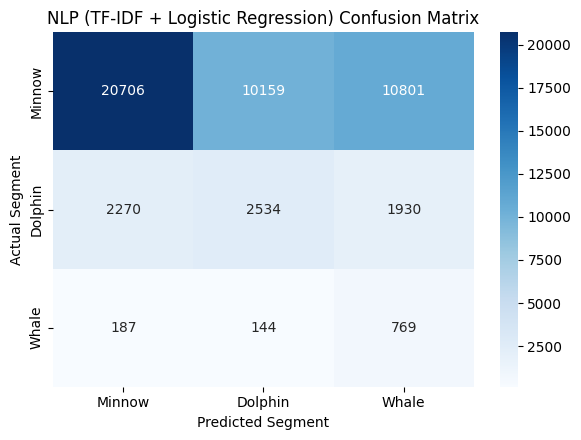

In [52]:
#10- Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order)
plt.title("NLP (TF-IDF + Logistic Regression) Confusion Matrix")
plt.xlabel("Predicted Segment")
plt.ylabel("Actual Segment")
plt.tight_layout()
plt.show()

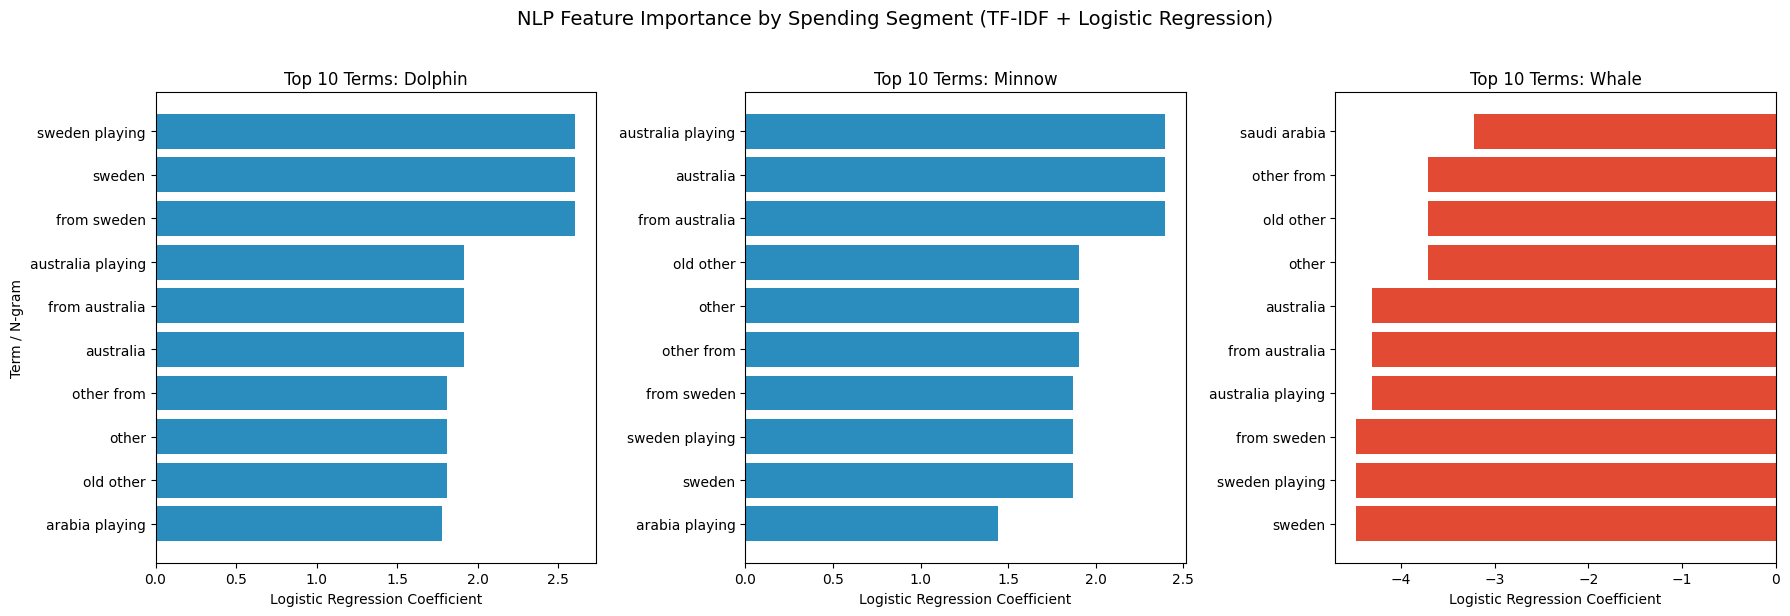

In [53]:
#11- Extract TF-IDF vocabulary and fitted Logistic Regression classifier from the pipeline
vectorizer = nlp_pipeline.named_steps["tfidf"]
classifier = nlp_pipeline.named_steps["clf"]
feature_names = np.array(vectorizer.get_feature_names_out())

# Create a 1x3 subplot layout to display top weighted terms for each spending segment
classes = classifier.classes_
fig, axes = plt.subplots(1, len(classes), figsize=(18, 6), sharex=False)

for idx, cls in enumerate(classes):
    # Get model coefficients for the current class and select the top 10 by magnitude
    coefs = classifier.coef_[idx]
    top_idx = np.argsort(np.abs(coefs))[::-1][:10]

    # Sort coefficients ascending (highest = Top)
    sub_df = pd.DataFrame({
        "Term": feature_names[top_idx],
        "Coef": coefs[top_idx],
    }).sort_values("Coef", ascending=True)

    # Plot horizontal bars (blue for positive weight, red for negative weight)
    ax = axes[idx]
    colors = np.where(sub_df["Coef"] >= 0, "#2b8cbe", "#e34a33")
    ax.barh(sub_df["Term"], sub_df["Coef"], color=colors)

    # Title & Labels
    ax.set_title(f"Top 10 Terms: {cls}")
    ax.set_xlabel("Logistic Regression Coefficient")
    if idx == 0:
        ax.set_ylabel("Term / N-gram")

# Add overall figure title, adjust layout, save chart, and render output
plt.suptitle("NLP Feature Importance by Spending Segment (TF-IDF + Logistic Regression)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("nlp_feature_importance_per_group.png", dpi=150, bbox_inches="tight")
plt.show()